In [16]:
import pymysql
import pandas as pd

# 数据库连接配置
db_config = {
    'host': '127.0.0.1',  # ⚠️ 如果数据库在 openEuler 虚拟机里，请改成 '127.0.0.1'
    'port': 3306,         # MySQL默认端口
    'user': 'root',
    'password': 'your-password',   # ⚠️ 确保这是你真实的密码
    'database': 'chat',
    'charset': 'utf8mb4'
}

try:
    # 建立数据库连接
    connection = pymysql.connect(**db_config)

    # 使用pandas的read_sql直接读取数据到DataFrame
    sql_query = "SELECT * FROM records"
    df = pd.read_sql(sql_query, connection)

    # 显示DataFrame的前几行
    print(df.head())

    print(f"\n✅ 成功读取数据，共计 {len(df)} 条记录！")

except pymysql.Error as e:
    print(f"❌ 数据库连接或查询失败：{e}")
except Exception as e:
    print(f"❌ 其他错误：{e}")
finally:
    # 确保连接被关闭
    if 'connection' in locals() and connection.open:
        connection.close()
        print("🔒 数据库连接已安全关闭。")

C:\Users\22866\AppData\Local\Temp\ipykernel_14460\2440311227.py:20: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql_query, connection)


   id                time                              records
0   1 2024-06-24 22:13:30  客服你好 满4减10的优惠券怎么用不了 是不是和别的活动冲突了 在线等
1   2 2024-06-01 20:55:42           急 会员价和普通价差多少洗面奶我开会员划算吗 在线等
2   3 2024-02-22 17:31:30          收货人姓名能改吗运动鞋写的不是本人 麻烦尽快回复 服了
3   4 2024-05-17 21:59:32      麻烦问一下 投诉了两次没人联系我瑜伽垫的处理结果到底什么时候给
4   5 2024-08-05 17:46:33     在吗 买的投影仪和详情页材质标注不一致 这个算不算虚假宣传 谢谢

✅ 成功读取数据，共计 84252 条记录！
🔒 数据库连接已安全关闭。


In [17]:
# 查看数据基本信息（列名、非空值数量、数据类型等）
print('\n数据基本信息：')
print(df.info())

# 查看数据维度（行数和列数）
print('\n数据维度：')
print(f"行数: {len(df)}, 列数: {len(df.columns)}")

# 查看各列的唯一值数量
print('\n各列的唯一值数量：')
print(df.nunique())

# 查看缺失值情况
print('\n缺失值统计：')
print(df.isnull().sum())


数据基本信息：
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84252 entries, 0 to 84251
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   id       84252 non-null  int64         
 1   time     84252 non-null  datetime64[ns]
 2   records  81636 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.9+ MB
None

数据维度：
行数: 84252, 列数: 3

各列的唯一值数量：
id         84252
time       84150
records    66862
dtype: int64

缺失值统计：
id            0
time          0
records    2616
dtype: int64


In [18]:
# 删除包含任何缺失值的行
df_cleaned = df.dropna()
# 查看处理后的数据信息
print("===== 删除缺失值后的数据信息 =====")
print(f"原始数据行数: {len(df)}, 处理后行数: {len(df_cleaned)}")
print(f"共删除了 {len(df) - len(df_cleaned)} 行")
print("\n处理后数据基本信息：")
print(df_cleaned.info())
print("\n处理后缺失值统计：")
print(df_cleaned.isnull().sum())

===== 删除缺失值后的数据信息 =====
原始数据行数: 84252, 处理后行数: 81636
共删除了 2616 行

处理后数据基本信息：
<class 'pandas.core.frame.DataFrame'>
Index: 81636 entries, 0 to 84251
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   id       81636 non-null  int64         
 1   time     81636 non-null  datetime64[ns]
 2   records  81636 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 2.5+ MB
None

处理后缺失值统计：
id         0
time       0
records    0
dtype: int64


In [19]:
# 确保time列是datetime类型（如果尚未转换）
df['time'] = pd.to_datetime(df['time'])
# 提取小时并统计
hourly_counts = df['time'].dt.hour.value_counts().sort_index()
# 结果展示
print("===== 按小时统计结果 =====")
print(hourly_counts)

===== 按小时统计结果 =====
time
0      428
1      412
2      440
3      458
4      425
5      859
6     1720
7     2896
8     4221
9     5740
10    6134
11    5458
12    4693
13    4986
14    5765
15    6109
16    5799
17    5087
18    4261
19    3787
20    4274
21    4556
22    3733
23    2011
Name: count, dtype: int64


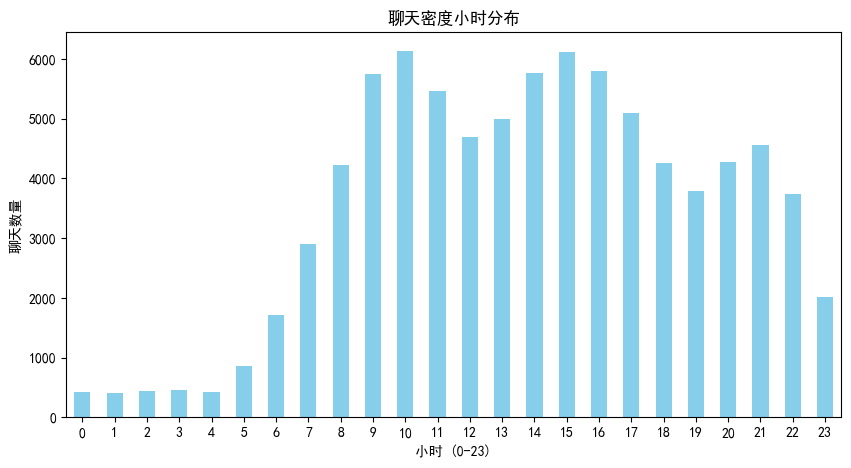

In [20]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# 解决中文字体显示问题
mpl.rcParams['font.sans-serif'] = ['SimHei'] # Windows 用户
mpl.rcParams['axes.unicode_minus'] = False

# 画柱状图
plt.figure(figsize=(10, 5))
hourly_counts.plot(kind='bar', color='skyblue')
plt.title('聊天密度小时分布')
plt.xlabel('小时 (0-23)')
plt.ylabel('聊天数量')
plt.xticks(rotation=0)
plt.show()

In [21]:
# 转换为DataFrame并整理格式
hourly_df = pd.DataFrame({
    '小时': [str(month)+'时' for month in hourly_counts.index],
    '消息数量': hourly_counts.values,
    '时间段': [f"{h}:00-{h+1}:00" for h in hourly_counts.index]
})

# 指定保存路径
save_path = r'D:\桌面\项目材料\基于Dify工作流的聊天助手搭建及智能数据分析项目\聊天助手\聊天密度小时分布.csv'  # 使用原始字符串避免转义问题

# 保存到CSV
hourly_df.to_csv(save_path, index=False, encoding='utf-8-sig')  # utf-8-sig支持Excel中文显示

print(f"数据已成功保存到: {save_path}")

数据已成功保存到: D:\桌面\项目材料\基于Dify工作流的聊天助手搭建及智能数据分析项目\聊天助手\聊天密度小时分布.csv


In [22]:
# 提取星期信息（中文显示）
weekday_map = {
    0: '周一',
    1: '周二',
    2: '周三',
    3: '周四',
    4: '周五',
    5: '周六',
    6: '周日'
}
df['weekday'] = df['time'].dt.weekday.map(weekday_map)
# 按星期计数并排序
weekday_order = ['周一', '周二', '周三', '周四', '周五', '周六', '周日']
weekday_counts = df['weekday'].value_counts().reindex(weekday_order)
# 结果展示
print("===== 按星期统计结果 =====")
print(weekday_counts)

===== 按星期统计结果 =====
weekday
周一    12067
周二    12036
周三    12277
周四    12001
周五    12178
周六    11915
周日    11778
Name: count, dtype: int64


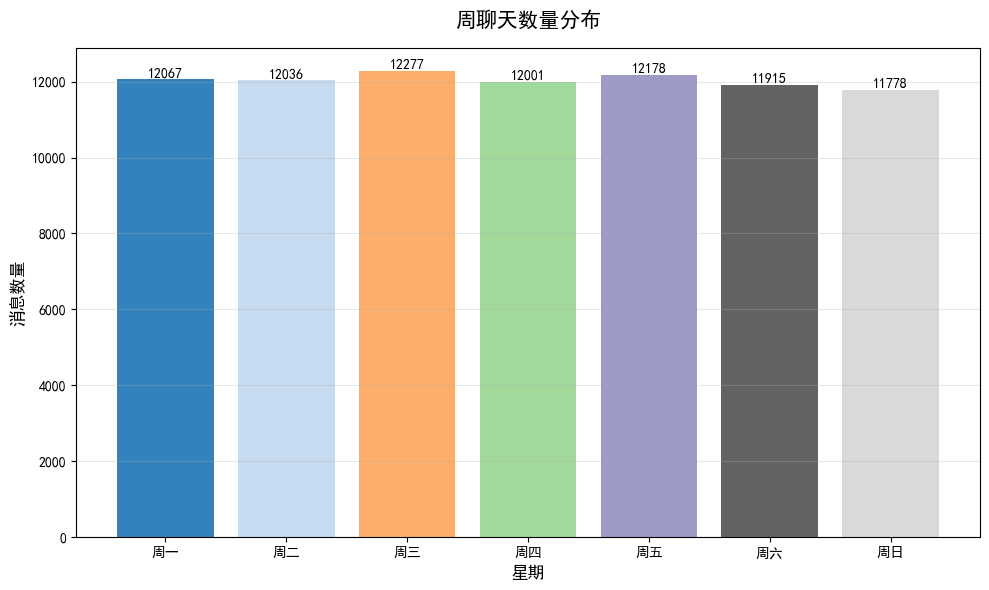

In [23]:
import numpy as np
plt.figure(figsize=(10, 6))
# 绘制柱状图
colors = plt.cm.tab20c(np.linspace(0, 1, 7))  # 使用渐变色
bars = plt.bar(weekday_counts.index, weekday_counts.values, color=colors)
# 添加数据标签
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}',
             ha='center', va='bottom',
             fontsize=10)
# 美化图表
plt.title('周聊天数量分布', fontsize=15, pad=15)
plt.xlabel('星期', fontsize=12)
plt.ylabel('消息数量', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
# 提取月份 (1-12)
df['month'] = df['time'].dt.month

# 按月统计记录数
monthly_counts = df['month'].value_counts().sort_index()

# 显示结果
print("==== 按月统计结果 ====")
print(monthly_counts)

==== 按月统计结果 ====
month
1     6345
2     6304
3     9718
4     9748
5     9650
6     9873
7     9632
8     9658
9     3327
10    3273
11    3350
12    3374
Name: count, dtype: int64


In [25]:
# 转换为DataFrame
monthly_df = pd.DataFrame({
    '月份': [str(month)+'月' for month in monthly_counts.index],
    '消息数量': monthly_counts.values
})

# ⚠️ 指定保存路径：建议直接写文件名，避开 C 盘权限报错
save_path = 'D:\桌面\项目材料\基于Dify工作流的聊天助手搭建及智能数据分析项目\聊天助手\聊天密度月分布.csv'

# 保存为CSV文件
monthly_df.to_csv(save_path, index=False, encoding='utf-8-sig')

=== 出现频率最高的10个词语 ===
一下: 31806次
麻烦: 17111次
你好: 16385次
这单: 9650次
还要: 9168次
谢谢: 9150次
在线: 9047次
尽快: 9023次
回复: 9023次
帮帮忙: 8932次


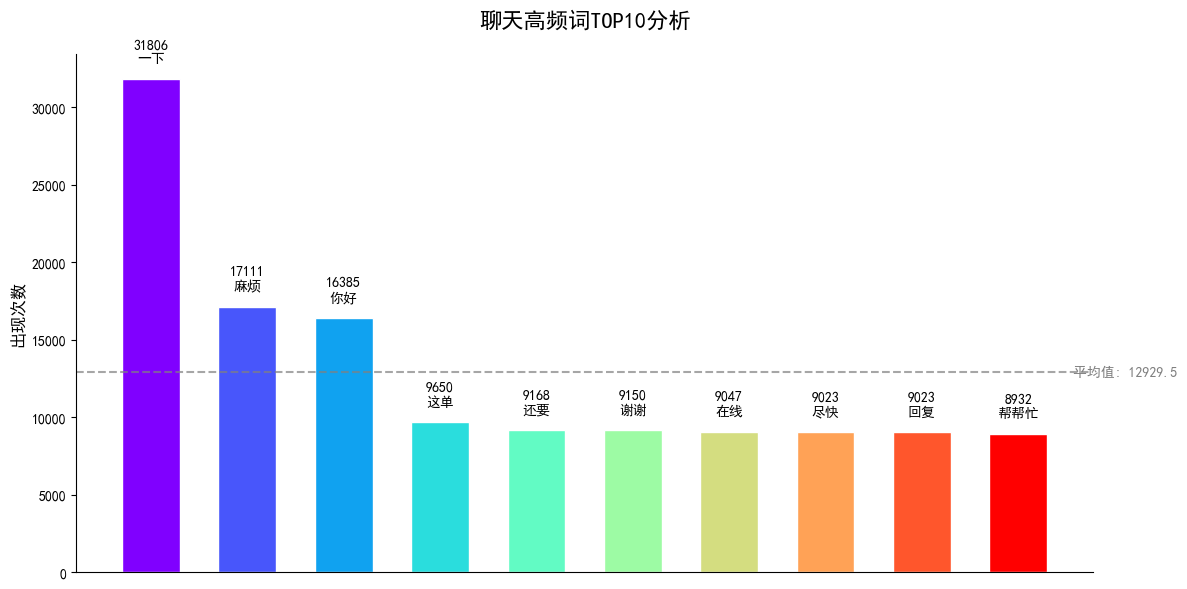

In [26]:
import jieba
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

# 合并所有文本内容
all_text = ''.join(df['records'].astype(str).tolist())

# 中文分词
words = jieba.lcut(all_text)

# 过滤单字和非中文字符（保留2字及以上词语）
filtered_words = [word for word in words if len(word) >= 2 and '\u4e00' <= word[0] <= '\u9fff']

# 统计词频
word_counts = Counter(filtered_words)

# 获取前10高频词
top10_words = word_counts.most_common(10)

# 显示结果
print("=== 出现频率最高的10个词语 ===")
for word, count in top10_words:
    print(f"{word}: {count}次")

# ===== 绘图部分 =====
words_list = [w[0] for w in top10_words]
counts_list = [w[1] for w in top10_words]

plt.figure(figsize=(12, 6))
# 使用彩虹色系
colors = plt.cm.rainbow(np.linspace(0, 1, len(words_list)))

# 绘制柱状图
bars = plt.bar(words_list, counts_list, color=colors, width=0.6, edgecolor='white')

# 添加数据标签和数值
for i, (word, count) in enumerate(top10_words):
    plt.text(i, count + max(counts_list)*0.03,
             f'{count}\n{word}',
             ha='center', va='bottom',
             fontsize=10,
             bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

# 隐藏顶部和右边框线
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# 添加标题和标签
plt.title('聊天高频词TOP10分析', fontsize=16, pad=20)
plt.ylabel('出现次数', fontsize=12)
plt.xticks([])  # 隐藏x轴标签（因为已经在柱子上显示）

# 添加平均线
mean_val = sum(counts_list)/len(counts_list)
plt.axhline(mean_val, color='gray', linestyle='--', alpha=0.7)
plt.text(len(words_list)-0.5, mean_val, f' 平均值: {mean_val:.1f}',
         va='center', ha='left', color='gray')

plt.tight_layout()
plt.show()

In [27]:
# 获取前100高频词
top100_words = word_counts.most_common(100)
words = []
word_count = []
for word, count in top100_words:
    words.append(word)
    word_count.append(count)

top100_words_df = pd.DataFrame({'词语': words, '次数': word_count})

# ⚠️ 指定保存路径：同样建议改成相对路径
save_path = '聊天词语频次数据.csv'

# 保存为CSV文件
top100_words_df.to_csv(save_path, index=False, encoding='utf-8-sig')

In [28]:
# 停用词文件路径
# ⚠️ 如果你电脑C盘没有 stopword.txt，这里会报错。
# 建议去网上下一个中文停用词表，放到你的代码同级目录，改成 'stopword.txt'
stopword_path = r'D:\桌面\项目材料\基于Dify工作流的聊天助手搭建及智能数据分析项目\聊天助手\stopword.txt'

stopwords = set()
try:
    with open(stopword_path, 'r', encoding='utf-8') as f:
        stopwords.update(line.strip() for line in f if line.strip())
except FileNotFoundError:
    print(f"错误: 文件 {stopword_path} 不存在")
except Exception as e:
    print(f"读取文件时出错: {str(e)}")

print(f"成功加载 {len(stopwords)} 个停用词")

错误: 文件 D:\桌面\项目材料\基于Dify工作流的聊天助手搭建及智能数据分析项目\聊天助手\stopword.txt 不存在
成功加载 0 个停用词


In [29]:
import jieba
import re
from collections import Counter

# 自定义过滤规则
def clean_text(text):
    # 去除特殊字符和标点（保留中文、英文、数字）
    text = re.sub(r'[^\w\u4e00-\u9fff]+', ' ', str(text))
    # 分词
    words = jieba.lcut(text)
    # 过滤条件：非停用词、非数字、长度大于1
    return [
        word for word in words
        if (word not in stopwords) and
           (not word.isdigit()) and
           (len(word) > 1)
    ]

# 应用到整个DataFrame
df['cleaned_words'] = df['records'].apply(clean_text)
print(df.head())

   id                time                              records weekday  month  \
0   1 2024-06-24 22:13:30  客服你好 满4减10的优惠券怎么用不了 是不是和别的活动冲突了 在线等      周一      6   
1   2 2024-06-01 20:55:42           急 会员价和普通价差多少洗面奶我开会员划算吗 在线等      周六      6   
2   3 2024-02-22 17:31:30          收货人姓名能改吗运动鞋写的不是本人 麻烦尽快回复 服了      周四      2   
3   4 2024-05-17 21:59:32      麻烦问一下 投诉了两次没人联系我瑜伽垫的处理结果到底什么时候给      周五      5   
4   5 2024-08-05 17:46:33     在吗 买的投影仪和详情页材质标注不一致 这个算不算虚假宣传 谢谢      周一      8   

                                 cleaned_words  
0   [客服, 你好, 优惠券, 怎么, 不了, 是不是, 别的, 活动, 冲突, 在线]  
1       [会员价, 普通, 价差, 多少, 洗面奶, 我开, 会员, 划算, 在线]  
2           [收货人, 姓名, 运动鞋, 不是, 本人, 麻烦, 尽快, 回复]  
3   [麻烦, 一下, 投诉, 两次, 联系, 瑜伽, 处理结果, 到底, 什么, 时候]  
4  [投影仪, 详情页, 材质, 标注, 一致, 这个, 算不算, 虚假, 宣传, 谢谢]  


In [30]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from wordcloud import WordCloud, ImageColorGenerator
from collections import Counter

# ================= 1. 数据准备 =================
# 展平所有分词列表
all_words = [word for sublist in df['cleaned_words'] for word in sublist]

# 计算词频（虽然这里没用上，但保留你的原逻辑）
word_freq = Counter(all_words)

# 转换为空格分隔的字符串
text = ' '.join(all_words)

# ================= 2. 加载形状蒙版 =================
# ⚠️ 你下载的 cloud.jpg 必须放在当前代码的文件夹里！
mask = np.array(Image.open(r'D:\桌面\项目材料\基于Dify工作流的聊天助手搭建及智能数据分析项目\聊天助手\蒙板\DM_20261020171907_001.png'))

# ================= 3. 创建词云对象 =================
wc = WordCloud(
    font_path='C:/Windows/Fonts/msyh.ttc',  # 绝对路径，防止字体找不到
    mask=mask,                              # 形状蒙版
    background_color='white',               # 背景色
    max_words=300,                          # 最大词数（调大一点更容易填满形状）
    max_font_size=150,                      # 最大字号
    colormap='Spectral'                     # 颜色方案
)

# 生成词云
wc.generate(text)

# ================= 4. 保存与显示 =================
# 保存在当前目录，避免 C 盘权限问题
save_dir = r"D:\桌面\项目材料\基于Dify工作流的聊天助手搭建及智能数据分析项目\聊天助手"

# 2. 检查并自动创建文件夹
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
    print(f"📁 文件夹不存在，已自动创建：{save_dir}")

# 3. 拼接完整的文件路径
output_path = os.path.join(save_dir, 'chat_wordcloud.png')

# 4. 保存图片
try:
    wc.to_file(output_path)
    print(f"✅ 词云图片已成功保存至: {output_path}")
except Exception as e:
    print(f"❌ 保存失败，错误原因: {e}")
    # 如果还是报错，就存到当前代码目录下作为退路
    wc.to_file('chat_wordcloud.png')
    print("⚠️ 已更改保存路径至当前代码目录: chat_wordcloud.png")

✅ 词云图片已成功保存至: D:\桌面\项目材料\基于Dify工作流的聊天助手搭建及智能数据分析项目\聊天助手\chat_wordcloud.png
